# Trading simulation: risk without direction

Our models cannot predict the **direction** of Bitcoin's moves (next-day AUC ≈ 0.50), but they predict the **size** of the moves well. This notebook asks what that is worth to a trader with **$10,000**: if we do not know where the price goes, can we at least know **how much we can lose, when, and therefore how much to buy, and with how much leverage**?

Four flows trade with **identical rules** and differ in one thing only, the estimate of tomorrow's risk:

| Flow | Risk estimate for the next day |
|---|---|
| **A: no model** | realised volatility of the last 7 days (what anyone can compute) |
| **B: GB** | Gradient Boosting forecast of the next day's volatility, refitted every month on all past days (weights halve every 12 months) |
| **C: Timestral** | Mistral's pretrained Timestral 28M, zero-shot, with the setting chosen in `timestral-zero-shot.ipynb` |
| **D: GB + Timestral** | the average of B and C (geometric mean of their volatilities) |

The rule parameters are fixed in advance, not tuned. The validation block (Jan 2023 → Jun 2024, a strong bull market) and the test block (Jul 2024 → Oct 2026, mostly sideways) are both out-of-sample for every forecast, so they are two independent trading periods. Section 3 measures **money**, section 4 measures **safety**, section 5 concludes.

Run from the repo root. The Timestral forecasts take ~50 minutes on a CPU the first time and are then cached in `data/timestral_cache/`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import xlogy
from scipy.stats import chi2
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from utils.config import DATA_START, VAL_START, TEST_START

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 1. Data and daily features

Hourly candles from `data/btc_hourly.csv.gz`, from `DATA_START` (1 Jan 2020); 210 days before it are read only so that the 50-day trend mean exists on day one. A **day** is a UTC calendar day. Features are known at the **end** of day *t* and used for the decision for day *t* + 1. Targets: the next day's log return (`y_r`) and log realised volatility (`y_lrv`, from its 24 hourly returns).

In [2]:
HOURLY = pd.read_csv("data/btc_hourly.csv.gz", index_col="Timestamp", parse_dates=True)   # 1 Jan 2018 → Oct 2026
hourly = HOURLY.loc[DATA_START - pd.Timedelta(days=210):]
close = hourly["Close"]
lr = np.log(close).diff() * 100                                     # hourly log return, %

day = pd.DataFrame({
    "r": lr.resample("D").sum(),                                     # log return of the day, %
    "rv": np.sqrt((lr ** 2).resample("D").sum()),                    # realised volatility of the day, %
    "rng": (np.log(hourly["High"].resample("D").max()) - np.log(hourly["Low"].resample("D").min())) * 100,
    "vol": np.log1p(hourly["Volume"].resample("D").sum()),
    "close": np.log(close.resample("D").last()),
}).iloc[:-1]                                                         # the last day is incomplete

F = pd.DataFrame(index=day.index)
for k in (1, 2, 3, 7, 14, 30):
    F[f"ret{k}"] = day["r"].rolling(k).sum()
for k in (1, 3, 7, 30):
    F[f"lrv{k}"] = np.log(np.sqrt((day["rv"] ** 2).rolling(k).mean()))
F["lrng"] = np.log(day["rng"])
F["vol_ratio"] = day["vol"] - day["vol"].rolling(30).mean()
F["down7"] = np.log(1e-3 + np.sqrt((day["r"].clip(upper=0) ** 2).rolling(7).mean()))   # downside volatility
F["wd_next"] = (day.index + pd.Timedelta(days=1)).dayofweek
F["trend50"] = (day["close"] - day["close"].rolling(50).mean() > 0).astype(float)
F["y_r"] = day["r"].shift(-1)
F["y_lrv"] = np.log(day["rv"]).shift(-1)
F = F.loc[DATA_START:]
X = ["ret1", "ret2", "ret3", "ret7", "ret14", "ret30", "lrv1", "lrv3", "lrv7", "lrv30",
     "lrng", "vol_ratio", "down7", "wd_next"]
BLOCKS = {"validation": (VAL_START, TEST_START - pd.Timedelta(days=1)), "test": (TEST_START, F.index[-2])}
print(f"{len(F):,} days, {F.index[0].date()} → {F.index[-1].date()}")

2,472 days, 2020-01-01 → 2026-10-07


## 2. The four risk forecasts

All forecasts exist from September 2022 (`RISK_START`), four months before the validation block, so that the calibration below already has history on the first day of validation.

- **B** is refitted at the start of every month on the days whose target is already known.
- **C** reads the last 180 days of the hourly |r|, with the clock (categorical), the release hours (known in advance) and the range and volume of the past hours. At 23:00 of every day it forecasts 21 quantiles of each of the next 24 hourly |r|. Their mean gives E|r| per hour, σ per hour ≈ E|r| · √(π/2), and the day's σ = √(Σ σ²). Timestral never sees our data.
- **D** is the daily analogue of the ensemble of `timestral-zero-shot.ipynb`, which averages the hourly forecasts of the monthly Gradient Boosting and Timestral.

In [3]:
RISK_START = pd.Timestamp("2022-09-01")

sig_A = np.exp(F["lrv7"])                                            # A: last 7 days

sig_B = pd.Series(np.nan, index=F.index)                             # B: monthly refitted Gradient Boosting
for m0 in pd.date_range(RISK_START, F.index[-1], freq="MS"):
    fit = F.loc[:m0 - pd.Timedelta(days=2)].dropna(subset=X + ["y_lrv"])     # targets known before the month
    gb = HistGradientBoostingRegressor(learning_rate=0.05, max_depth=3, min_samples_leaf=40, max_iter=300, random_state=42)
    gb.fit(fit[X], fit["y_lrv"], sample_weight=0.5 ** ((m0 - fit.index).days.values / 365))
    rows = F.loc[m0 - pd.Timedelta(days=1): m0 + pd.offsets.MonthBegin(1) - pd.Timedelta(days=2)]
    sig_B.loc[rows.index] = np.exp(gb.predict(rows[X]))

TS_CACHE = os.path.join("data", "timestral_cache", "trading_daily_23h.npz")

def timestral_daily(start=RISK_START - pd.Timedelta(days=2)):
    # Timestral 28M with the setting of timestral-zero-shot.ipynb: quantiles of the 24 hourly |r| after 23:00 of each day
    import torch
    from timestral import TimestralForecaster
    from utils import hourly as U
    from utils.features import TARGET_HOUR_FEATURES, load_releases, target_hour_features
    h = HOURLY.loc[DATA_START:]
    CTX = PAD = 4320                                                 # 180 days
    ext = pd.date_range(h.index[0] - PAD * pd.Timedelta(hours=1), h.index[-1], freq="h")
    pad = lambda a: np.r_[np.full(PAD, np.nan), np.asarray(a, dtype=float)]
    cat = np.vstack([ext.hour, ext.dayofweek]).astype(float)
    rel = target_hour_features(ext, load_releases())[list(TARGET_HOUR_FEATURES)].values.T.astype(float)
    past = np.vstack([pad((h["High"] - h["Low"]) / h["Close"] * U.PCT), pad(np.log1p(h["Volume"].clip(lower=0)))])
    series = pad(np.abs(h["Return"].values * U.PCT))
    org = np.where((h.index.hour == 23) & (h.index >= start))[0]
    org = org[org + 24 < len(h)]
    fc = TimestralForecaster.from_pretrained("mistralai/Timestral-28M", device=torch.device("cuda" if torch.cuda.is_available() else "cpu"))
    step, out = 256 // (1 + 2 + len(TARGET_HOUR_FEATURES) + 2), []
    for i in range(0, len(org), step):
        p = org[i:i + step] + PAD
        ci, ai = p[:, None] + np.arange(-CTX + 1, 1), p[:, None] + np.arange(-CTX + 1, 25)
        f = fc.forecast(series[ci].astype(np.float32), prediction_length=24,
                        categorical_known_covariates=cat[:, ai].transpose(1, 0, 2).astype(np.float64),
                        known_covariates=rel[:, ai].transpose(1, 0, 2).astype(np.float32),
                        past_covariates=past[:, ci].transpose(1, 0, 2).astype(np.float32))
        out.append(f.quantiles[:, 0].float().cpu().numpy())
    os.makedirs(os.path.dirname(TS_CACHE), exist_ok=True)
    np.savez(TS_CACHE, q=np.concatenate(out), origin=h.index[org].values.astype("datetime64[ns]"),
             levels=np.array(fc.quantile_levels))

if not os.path.exists(TS_CACHE):
    timestral_daily()
ts = np.load(TS_CACHE)
lv = np.r_[0.0, ts["levels"], 1.0]                                   # trapezoid weights of the quantiles
qw = (lv[2:] - lv[:-2]) / 2; qw[0] += ts["levels"][0] / 2; qw[-1] += (1 - ts["levels"][-1]) / 2
e_abs = np.abs(ts["q"]) @ qw                                         # E|r| of each of the 24 hours, %
sig_C = pd.Series(np.sqrt(((e_abs * np.sqrt(np.pi / 2)) ** 2).sum(axis=1)),
                  index=pd.DatetimeIndex(ts["origin"]).normalize()).reindex(F.index)   # by decision day
sig_D = np.sqrt(sig_B * sig_C)
SIG = {"A: no model": sig_A, "B: GB": sig_B, "C: Timestral": sig_C, "D: GB + Timestral": sig_D}

**From volatility to a loss.** Every flow turns its σ into **L**, the fall of the price that the next day should exceed only 10% of the time, with the same **rolling calibration**: L = c · σ, where c is the 90% quantile of (realised fall / σ) over the last 90 days whose outcome is already known. This is the rolling conformal idea of `classical-models.ipynb`, applied identically to every flow.

In [4]:
def loss_q10(sig, window=90):
    z = -F["y_r"] / sig                                              # realised fall in units of the forecast
    c = z.shift(1).rolling(window, min_periods=60).quantile(0.90)    # only outcomes known at decision time
    return (c * sig).clip(lower=0.3)

L = {n: loss_q10(s) for n, s in SIG.items()}
FLOWS = list(L)
for n, l in L.items():
    assert l.loc[VAL_START - pd.Timedelta(days=1): F.index[-2]].notna().all(), n

### 2.1 How good is each risk forecast?

Correlation and R² between the forecast and tomorrow's log volatility (R² after removing the constant bias, which the calibration removes anyway), and the mean loss level L: a sharper forecast gives a lower L on calm days and a higher one on wild days.

In [5]:
rows = []
for b, (a, z) in BLOCKS.items():
    d = F.loc[a:z]
    for n in FLOWS:
        s = np.log(SIG[n].loc[a:z])
        rows.append({"block": b, "flow": n, "corr": np.corrcoef(s, d["y_lrv"])[0, 1],
                     "R² log-vol": r2_score(d["y_lrv"], s + (d["y_lrv"] - s).mean()), "mean L %": L[n].loc[a:z].mean()})
pd.DataFrame(rows).set_index(["block", "flow"]).round(3)

corr  R² log-vol  mean L %
block      flow                                          
validation A: no model        0.423       0.152     2.276
           B: GB              0.639       0.400     2.162
           C: Timestral       0.704       0.494     2.256
           D: GB + Timestral  0.698       0.487     2.193
test       A: no model        0.447       0.173     2.708
           B: GB              0.734       0.537     2.732
           C: Timestral       0.741       0.548     2.733
           D: GB + Timestral  0.755       0.570     2.719

## 3. Trading with $10,000: money

| Rule | Value |
|---|---|
| Starting capital | **$10,000**, spot, long or cash, no shorting |
| Decision | once a day at 00:00 UTC, with the information of the end of the previous day |
| Entry filter | long only when the price is above its 50-day mean (**trend**), otherwise cash |
| **Position size** | the share **w = min(1, budget / L)** of the equity, so that a bad day (the 10% worst case L) costs about **budget = 1.5%** of the equity ($150 at the start) |
| **Stop-loss** | checked every hour: if the price falls **1.5 · L** below the day's open, sell at that hour's close and stay in cash until the next day |
| Rebalancing band | the position changes only if w moves by more than 10 percentage points (or to/from 0) |
| Fees | **0.10% per side** of the traded value |

Two baselines without any risk control: **buy & hold** and **trend only** (fully invested whenever the price is above its 50-day mean).

In [6]:
P = dict(capital=10_000, fee=0.10, budget=1.5, stop_mult=1.5, band=0.10)

def simulate(Lhat, a, z, p=P, trend=True, stop=True, sizing=True):
    cash, btc, w_held = p["capital"], 0.0, 0.0
    out = []
    for d in F.loc[a - pd.Timedelta(days=1): z - pd.Timedelta(days=1)].index:     # decided at the end of day d
        nd = d + pd.Timedelta(days=1)
        hrs = close.loc[nd: nd + pd.Timedelta(hours=23)]
        open_px = close.loc[nd - pd.Timedelta(hours=1)]
        eq0 = cash + btc * open_px
        Lh = Lhat.loc[d]
        w = (F.loc[d, "trend50"] if trend else 1.0) * (min(1.0, p["budget"] / Lh) if sizing else 1.0)
        if w == 0 or w_held == 0 or abs(w - w_held) > p["band"]:
            w_held = w
        tgt = w_held * eq0 / open_px
        fee = abs(tgt - btc) * open_px * p["fee"] / 100
        cash += (btc - tgt) * open_px - fee
        btc, fees, stopped = tgt, fee, False
        if stop and btc > 0:
            hit = np.log(hrs / open_px) * 100 <= -p["stop_mult"] * Lh
            if hit.any():
                px = hrs[hit].iloc[0]
                f = btc * px * p["fee"] / 100
                cash += btc * px - f; fees += f; btc, stopped = 0.0, True
        eq1 = cash + btc * hrs.iloc[-1]
        out.append(dict(day=nd, eq_start=eq0, equity=eq1, pnl=eq1 - eq0, w=w_held, stopped=stopped, fees=fees,
                        day_r=np.log(hrs.iloc[-1] / open_px) * 100))
        if stopped:
            w_held = 0.0
    return pd.DataFrame(out).set_index("day")

def equity(r):
    return pd.concat([pd.Series([P["capital"]], index=[r.index[0] - pd.Timedelta(days=1)]), r["equity"]])

def money(r):
    eq = equity(r)
    ret = eq.pct_change().dropna()
    return {"end $": eq.iloc[-1], "ann. return %": ((eq.iloc[-1] / P["capital"]) ** (365 / len(r)) - 1) * 100,
            "Sharpe": ret.mean() / ret.std() * np.sqrt(365), "max DD %": (eq / eq.cummax() - 1).min() * 100,
            "worst day $": r["pnl"].min(), "fees $": r["fees"].sum(), "avg invested %": r["w"].mean() * 100}

RUNS = {}
for b, (a, z) in BLOCKS.items():
    RUNS[(b, "Buy & hold")] = simulate(L["A: no model"], a, z, trend=False, stop=False, sizing=False)
    RUNS[(b, "Trend only")] = simulate(L["A: no model"], a, z, stop=False, sizing=False)
    for n in FLOWS:
        RUNS[(b, n)] = simulate(L[n], a, z)
res = pd.DataFrame({k: money(v) for k, v in RUNS.items()}).T
res.index.names = ["block", "strategy"]
res.round(2)

end $  ann. return %  Sharpe  max DD %  worst day $   fees $  avg invested %
block      strategy                                                                                          
validation Buy & hold         37883.34         143.21    2.09    -20.33     -3454.93    10.01          100.00
           Trend only         32113.15         117.82    2.11    -15.35     -2922.75   468.09           67.64
           A: no model        23151.47          75.10    2.09    -13.82     -1209.71  1212.63           48.18
           B: GB              19328.31          55.23    1.75    -16.31      -712.63  1528.57           48.94
           C: Timestral       18851.62          52.66    1.81    -14.68      -709.89  1480.47           46.93
           D: GB + Timestral  20242.55          60.09    1.92    -14.89      -734.35  1497.02           48.08
test       Buy & hold         13636.49          14.65    0.53    -53.08     -1626.59    10.01          100.00
           Trend only         16189.83          23.66    0.87    -25.48     -1062.32   678.01           54.23
           A: no model        12387.61           9.90    0.56    -21.47      -468.42   956.19           38.54
           B: GB              11812.73           7.62    0.49    -22.03      -400.05  1139.78           37.74
           C: Timestral       12178.90           9.08    0.55    -19.45      -327.11  1167.26           38.07
           D: GB + Timestral  12277.65           9.47    0.58    -20.44      -350.38  1143.70           37.74

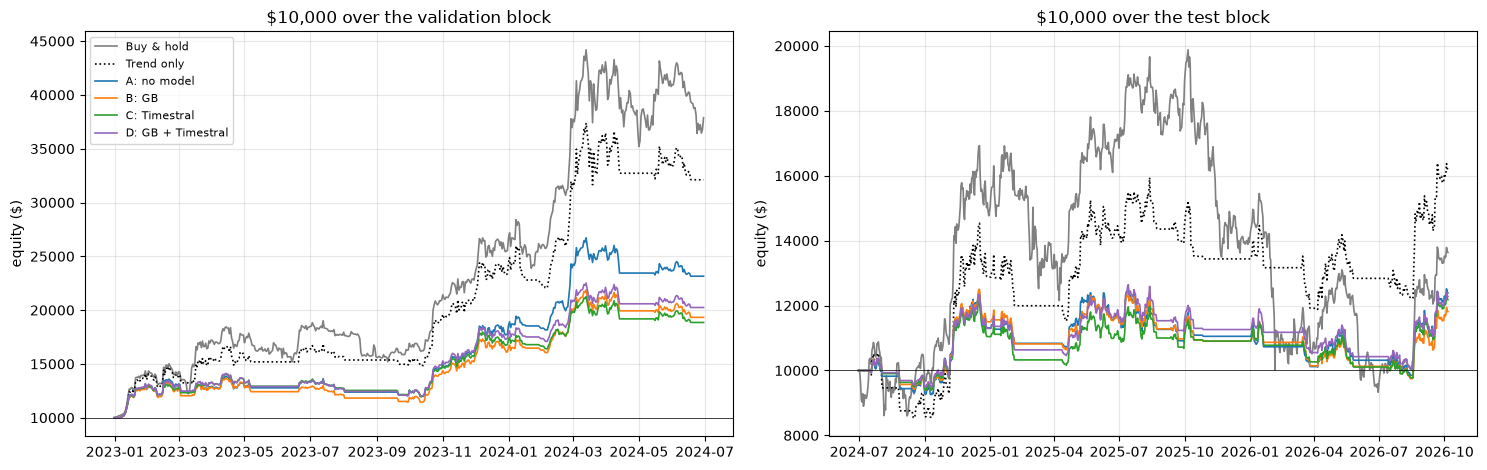

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
styles = {"Buy & hold": ("grey", "-"), "Trend only": ("black", ":"), "A: no model": ("tab:blue", "-"),
          "B: GB": ("tab:orange", "-"), "C: Timestral": ("tab:green", "-"), "D: GB + Timestral": ("tab:purple", "-")}
for ax, b in zip(axes, BLOCKS):
    for s, (col, ls) in styles.items():
        ax.plot(equity(RUNS[(b, s)]), color=col, ls=ls, lw=1.2, label=s)
    ax.axhline(P["capital"], color="k", lw=0.5)
    ax.set_title(f"$10,000 over the {b} block"); ax.set_ylabel("equity ($)"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.1 Is any model flow reliably better than A?

Paired block bootstrap of the daily returns (blocks of 20 days, 2,000 resamples): the 95% interval of the Sharpe difference against flow A. Then the same comparison **without fees**, and a count over 12 other settings of budget (1, 1.5, 2.5%) and stop (1, 1.5, 2.5 · L, none), to check that the answer does not depend on the chosen parameters.

In [8]:
def boot_sharpe_diff(ra, rb, n=2000, block=20, seed=0):
    rng = np.random.default_rng(seed)
    a, b, T = ra.values, rb.values, len(ra)
    idx = (rng.integers(0, T, (n, T // block + 1))[:, :, None] + np.arange(block)).reshape(n, -1)[:, :T] % T
    d = (b[idx].mean(1) / b[idx].std(1) - a[idx].mean(1) / a[idx].std(1)) * np.sqrt(365)
    return np.percentile(d, [2.5, 97.5])

daily = lambda r: r["pnl"] / r["eq_start"]
rows = []
for b, (a, z) in BLOCKS.items():
    free = {n: money(simulate(L[n], a, z, p=dict(P, fee=0.0))) for n in FLOWS}
    grid = {n: [money(simulate(L[n], a, z, p=dict(P, budget=bu, stop_mult=sm or 0), stop=sm is not None))["end $"]
                for bu in (1.0, 1.5, 2.5) for sm in (1.0, 1.5, 2.5, None)] for n in FLOWS}
    for n in FLOWS[1:]:
        lo, hi = boot_sharpe_diff(daily(RUNS[(b, FLOWS[0])]), daily(RUNS[(b, n)]))
        rows.append({"block": b, "flow": n,
                     "end $ − A": res.loc[(b, n), "end $"] - res.loc[(b, FLOWS[0]), "end $"],
                     "Sharpe − A": res.loc[(b, n), "Sharpe"] - res.loc[(b, FLOWS[0]), "Sharpe"],
                     "95% CI Sharpe − A": f"[{lo:+.2f}, {hi:+.2f}]",
                     "no fees: end $ − A": free[n]["end $"] - free[FLOWS[0]]["end $"],
                     "settings with more $ than A": f"{sum(x > y for x, y in zip(grid[n], grid[FLOWS[0]]))} / 12"})
pd.DataFrame(rows).set_index(["block", "flow"]).round(2)

end $ − A  Sharpe − A 95% CI Sharpe − A  no fees: end $ − A settings with more $ than A
block      flow                                                                                                      
validation B: GB               -3823.16       -0.34    [-0.69, +0.03]            -3522.56                      1 / 12
           C: Timestral        -4299.86       -0.28    [-0.72, +0.18]            -4147.46                      1 / 12
           D: GB + Timestral   -2908.93       -0.17    [-0.56, +0.24]            -2653.25                      1 / 12
test       B: GB                -574.88       -0.08    [-0.41, +0.27]             -404.95                      0 / 12
           C: Timestral         -208.71       -0.01    [-0.31, +0.29]               54.40                      3 / 12
           D: GB + Timestral    -109.96        0.01    [-0.31, +0.33]               97.68                      0 / 12

### 3.2 Why a better risk forecast does not pay

A risk-sized position is only smaller or larger, never on the other side. The table splits the days by how much more (or less) each model flow invested than flow A, and shows what Bitcoin did on those days.

In [9]:
rows = []
for b in BLOCKS:
    ra = RUNS[(b, FLOWS[0])]
    for n in FLOWS[1:]:
        diff = RUNS[(b, n)]["w"] - ra["w"]
        for lab, m in [("invests ≥ 20 pp less than A", diff <= -0.2), ("invests ≥ 20 pp more than A", diff >= 0.2)]:
            rows.append({"block": b, "flow": n, "days": lab, "n": int(m.sum()),
                         "mean |BTC move| %": ra.loc[m, "day_r"].abs().mean(), "mean BTC return %": ra.loc[m, "day_r"].mean()})
pd.DataFrame(rows).set_index(["block", "flow", "days"]).round(2)

n  mean |BTC move| %  mean BTC return %
block      flow              days                                                                 
validation B: GB             invests ≥ 20 pp less than A  37               2.35               0.08
                             invests ≥ 20 pp more than A  59               1.13               0.15
           C: Timestral      invests ≥ 20 pp less than A  62               2.44               0.49
                             invests ≥ 20 pp more than A  62               1.01              -0.07
           D: GB + Timestral invests ≥ 20 pp less than A  37               2.86               0.38
                             invests ≥ 20 pp more than A  50               0.88              -0.03
test       B: GB             invests ≥ 20 pp less than A  65               1.71              -0.11
                             invests ≥ 20 pp more than A  71               1.05              -0.00
           C: Timestral      invests ≥ 20 pp less than A  49               1.46              -0.06
                             invests ≥ 20 pp more than A  63               0.84               0.15
           D: GB + Timestral invests ≥ 20 pp less than A  62               1.52              -0.17
                             invests ≥ 20 pp more than A  68               0.87               0.09

## 4. Trading with $10,000: safety

### 4.1 Does the loss limit hold? (VaR backtest)

Every flow promises daily: "the price falls more than **L** on only 10% of days", a 10% Value-at-Risk. Two standard bank tests check the promise; p < 0.05 rejects it:
- **Kupiec:** is the share of breaches compatible with 10%?
- **Christoffersen:** are the breaches independent, or do they come in dangerous clusters?

In dollars: how far the trading run lost beyond its $-limit (1.5% of the equity) on the days it broke it.

In [10]:
def kupiec(hit, p=0.10):
    n, x = len(hit), hit.sum()
    return chi2.sf(-2 * (xlogy(n - x, 1 - p) + xlogy(x, p) - xlogy(n - x, 1 - x / n) - xlogy(x, x / n)), 1)

def christoffersen(hit):
    h = hit.astype(int).values
    a, b = h[:-1], h[1:]
    n00, n01, n10, n11 = [((a == i) & (b == j)).sum() for i in (0, 1) for j in (0, 1)]
    p01, p11, pi = n01 / (n00 + n01), n11 / max(n10 + n11, 1), (n01 + n11) / len(a)
    lr = -2 * (xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
               - xlogy(n00, 1 - p01) - xlogy(n01, p01) - xlogy(n10, 1 - p11) - xlogy(n11, p11))
    return chi2.sf(lr, 1), p11

rows = []
for b, (a, z) in BLOCKS.items():
    d = F.loc[a:z]
    calm = d["lrv7"] < d["lrv7"].median()
    for n in FLOWS:
        hit = d["y_r"] < -L[n].loc[a:z]
        p_ind, p11 = christoffersen(hit)
        r = RUNS[(b, n)]
        beyond = -r["pnl"] - P["budget"] / 100 * r["eq_start"]
        rows.append({"block": b, "flow": n, "breaches %": hit.mean() * 100, "Kupiec p": kupiec(hit),
                     "Christoffersen p": p_ind, "P(breach | breach yesterday) %": p11 * 100,
                     "calm weeks %": hit[calm].mean() * 100, "wild weeks %": hit[~calm].mean() * 100,
                     "mean $ beyond limit": beyond[beyond > 0].mean(), "max $ beyond limit": beyond.max()})
pd.DataFrame(rows).set_index(["block", "flow"]).round(2)

breaches %  Kupiec p  Christoffersen p  P(breach | breach yesterday) %  calm weeks %  wild weeks %  mean $ beyond limit  max $ beyond limit
block      flow                                                                                                                                                          
validation A: no model             10.79      0.54              0.48                           13.56         11.36         10.22               222.25              839.91
           B: GB                   12.43      0.07              0.56                           10.29         13.19         11.68               173.13              396.34
           C: Timestral            10.79      0.54              0.26                            6.78         11.72          9.85               165.51              411.46
           D: GB + Timestral       11.15      0.38              0.42                            8.20         11.72         10.58               177.99              414.51
test       A: no model             11.35      0.20              0.14                           16.13         14.01          8.70                86.17              292.32
           B: GB                    9.90      0.93              0.71                           11.11         10.87          8.94                73.09              214.33
           C: Timestral            10.39      0.71              0.01                           18.82         12.08          8.70                67.86              155.48
           D: GB + Timestral       10.39      0.71              0.26                           14.12         11.84          8.94                68.85              161.49

### 4.2 Tail losses in dollars

Worst day, week and month, **expected shortfall** (the average of the 1% worst days), maximum drawdown and the longest time **under water** (days until the equity is back at its previous high). All flows invest about the same share on average (section 3), so the comparison is fair.

In [11]:
def tail(r):
    eq = equity(r)
    dd = eq / eq.cummax() - 1
    under = (dd < 0).astype(int)
    longest = under.groupby((under == 0).cumsum()).sum().max()
    return {"worst day $": r["pnl"].min(), "worst week $": eq.diff(7).min(), "worst month $": eq.diff(30).min(),
            "ES 1% $": r["pnl"][r["pnl"] <= r["pnl"].quantile(0.01)].mean(), "max DD %": dd.min() * 100,
            "longest under water (days)": longest}

pd.DataFrame({(b, n): tail(RUNS[(b, n)]) for b in BLOCKS for n in ["Trend only"] + FLOWS}).T.round(1)

worst day $  worst week $  worst month $  ES 1% $  max DD %  longest under water (days)
validation Trend only             -2922.8       -4896.5        -3897.9  -2194.3     -15.3                       109.0
           A: no model            -1209.7       -2566.0        -2566.0   -829.2     -13.8                       187.0
           B: GB                   -712.6       -1712.9        -1712.9   -645.8     -16.3                       191.0
           C: Timestral            -709.9       -1689.8        -1689.8   -613.3     -14.7                       191.0
           D: GB + Timestral       -734.3       -1787.7        -1787.7   -634.7     -14.9                       191.0
test       Trend only             -1062.3       -1550.0        -1794.7   -695.9     -25.5                       403.0
           A: no model             -468.4       -1043.9        -1163.0   -353.8     -21.5                       449.0
           B: GB                   -400.0        -964.4        -1069.6   -331.4     -22.0                       658.0
           C: Timestral            -327.1        -965.6        -1115.9   -300.9     -19.4                       642.0
           D: GB + Timestral       -350.4        -946.2        -1036.8   -314.7     -20.4                       449.0

### 4.3 How likely is a large drawdown within a year? (Monte Carlo)

Each flow's daily returns are resampled into 5,000 alternative years (365 days in blocks of 20 consecutive days, which keeps the clustering of volatility; the same blocks for every flow). For each year: the maximum drawdown.

In [12]:
def monte_carlo(runs, n=5000, days=365, block=20, seed=1):
    rng = np.random.default_rng(seed)
    T = len(next(iter(runs.values())))
    idx = (rng.integers(0, T, (n, days // block + 1))[:, :, None] + np.arange(block)).reshape(n, -1)[:, :days] % T
    out = {}
    for k, r in runs.items():
        eq = np.cumprod(1 + daily(r).values[idx], axis=1)
        dd = (eq / np.maximum.accumulate(np.maximum(eq, 1), axis=1) - 1).min(axis=1)
        out[k] = {"P(DD > 10%)": (dd < -0.10).mean() * 100, "P(DD > 20%)": (dd < -0.20).mean() * 100,
                  "P(DD > 30%)": (dd < -0.30).mean() * 100, "median DD %": np.median(dd) * 100,
                  "95th pct DD %": np.percentile(dd, 5) * 100}
    return out

pd.DataFrame({(b, k): v for b in BLOCKS for k, v in monte_carlo({n: RUNS[(b, n)] for n in ["Trend only"] + FLOWS}).items()}).T.round(1)

P(DD > 10%)  P(DD > 20%)  P(DD > 30%)  median DD %  95th pct DD %
validation Trend only                98.9         36.1          5.1        -18.0          -30.1
           A: no model               86.3         15.3          1.0        -14.2          -24.5
           B: GB                     91.4         19.7          2.1        -15.1          -26.2
           C: Timestral              84.9         12.6          1.0        -13.6          -23.7
           D: GB + Timestral         85.1         12.0          0.8        -13.6          -23.4
test       Trend only                98.7         54.0         14.4        -20.6          -36.1
           A: no model               92.4         27.2          3.5        -16.0          -28.6
           B: GB                     87.7         23.3          2.9        -15.4          -27.8
           C: Timestral              87.5         23.3          3.1        -15.2          -27.6
           D: GB + Timestral         85.9         20.8          2.5        -14.8          -26.8

### 4.4 Leverage: how much can be used without being liquidated?

With futures, a long position with leverage *k* is **liquidated** when the price falls about 1/*k* minus the maintenance margin (0.5%) below the entry. The position is opened at the start of the day and closed at its end; the deepest fall uses the hourly **lows**, so intraday spikes count. With 2–5× nothing is ever liquidated (the deepest intraday fall in both blocks is ~15%), so we look at the range where liquidation is a real risk.

First **fixed leverage** without any forecast. Then the leverage is **set daily from each forecast**, so that the liquidation price lies m · L below the open (capped at 25×). Flows B–D get their own m so that their **average leverage equals flow A's**: at the same average leverage, the flow with fewer liquidations puts the leverage on the right days.

In [13]:
low, MM, CAP = hourly["Low"], 0.5, 25.0
DROP, rows = {}, []
for b, (a, z) in BLOCKS.items():
    days = F.loc[a - pd.Timedelta(days=1): z - pd.Timedelta(days=1)].index
    DROP[b] = pd.Series([-np.log(low.loc[d + pd.Timedelta(days=1): d + pd.Timedelta(hours=47)].min()
                                 / close.loc[d + pd.Timedelta(hours=23)]) * 100 for d in days], index=days)
    for k in (5, 10, 15, 20):
        liq = DROP[b] >= 100 / k - MM
        rows.append({"block": b, "leverage": f"{k}×", "liquidation distance %": 100 / k - MM,
                     "days liquidated": int(liq.sum()), "per year": liq.sum() / len(days) * 365})
pd.DataFrame(rows).set_index(["block", "leverage"]).round(2)

liquidation distance %  days liquidated  per year
block      leverage                                                   
validation 5×                         19.50                0      0.00
           10×                         9.50                3      2.00
           15×                         6.17               21     14.01
           20×                         4.50               45     30.03
test       5×                         19.50                0      0.00
           10×                         9.50                5      2.20
           15×                         6.17               26     11.46
           20×                         4.50               64     28.21

In [14]:
def liquidations(n, b, mA):
    drop = DROP[b]
    lev = lambda m, name: np.minimum(CAP, 100 / (m * L[name].loc[drop.index] + MM))
    target = lev(mA, FLOWS[0]).mean()
    lo, hi = 0.3, 10.0
    for _ in range(40):                                              # m of this flow with the same average leverage
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if lev(mid, n).mean() > target else (lo, mid)
    return int((drop >= 100 / lev(lo, n) - MM).sum()), target

rows = []
for b in BLOCKS:
    for mA in (1.5, 2, 3):
        row = {"block": b, "avg leverage": round(liquidations(FLOWS[0], b, mA)[1], 1)}
        row.update({n: liquidations(n, b, mA)[0] for n in FLOWS})
        rows.append(row)
pd.DataFrame(rows).set_index(["block", "avg leverage"])

A: no model  B: GB  C: Timestral  D: GB + Timestral
block      avg leverage                                                     
validation 23.1                   57     52            50                 53
           20.3                   37     36            35                 36
           14.9                   20     13            13                 12
test       21.5                   71     66            66                 66
           18.3                   48     32            34                 38
           13.1                   12      5             4                  3

## 5. More with Timestral

Four more uses of Timestral, all zero-shot and cached in `data/timestral_cache/`:

1. **Direction.** Does Timestral, given the signed returns, know where the price goes tomorrow, or in the next hour?
2. **A cheaper Timestral.** The daily realised-volatility series instead of 180 days of hourly data.
3. **Inside the day.** Stops and positions driven by the forecast of each of the 24 hours.
4. **Beyond tomorrow.** A forecast of the next 7 days as a second, weekly loss limit, aimed at the slow drawdowns that the next-day forecasts miss (section 4.2).

Without a GPU the forecasts of 5.1 with covariates take ~50 minutes, the others a few minutes.

In [15]:
H20 = HOURLY.loc[DATA_START:]
RET20 = H20["Return"].values * 100                                   # hourly simple return, %

def timestral_cached(name, series, org, ctx, horizon, step, covariates=None):
    # Timestral 28M quantiles (origins, horizon, 21) of `series` after each position in `org`, cached by name
    path = os.path.join("data", "timestral_cache", f"{name}.npz")
    if not os.path.exists(path):
        import torch
        from timestral import TimestralForecaster
        fc = TimestralForecaster.from_pretrained("mistralai/Timestral-28M", device=torch.device("cuda" if torch.cuda.is_available() else "cpu"))
        assert org.min() - ctx + 1 >= 0
        out = []
        for i in range(0, len(org), step):
            p = org[i:i + step]
            ci = p[:, None] + np.arange(-ctx + 1, 1)
            kw = covariates(p) if covariates else {}
            out.append(fc.forecast(series[ci].astype(np.float32), prediction_length=horizon, **kw).quantiles[:, 0].float().cpu().numpy())
        np.savez(path, q=np.concatenate(out), origin_pos=org, levels=np.array(fc.quantile_levels))
    return np.load(path)

ORG23 = np.where((H20.index.hour == 23) & (H20.index >= RISK_START - pd.Timedelta(days=2)))[0]   # 23:00 of every day

### 5.1 Does Timestral know the direction?

Timestral reads the last 180 days of the **signed** hourly return r and forecasts the 21 quantiles of each of the next 24 hours. It is run twice: without covariates, and with those chosen for |r| in `timestral-zero-shot.ipynb` (clock, release hours, range and volume). Three daily signals are tested: the expected return of the day (sum of the 24 hourly means), the sum of the medians, and the **tail asymmetry** (q90 + q10 summed over the day: positive when the upside tail is larger than the downside tail). Then the next hour, against the reversal rule of `classical-models.ipynb`. Finally, the signal is traded with no tuning, buying only when the expected return of the day is positive.

In [16]:
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

PADR = 4320
ext = pd.date_range(H20.index[0] - PADR * pd.Timedelta(hours=1), H20.index[-1], freq="h")
padr = lambda a: np.r_[np.full(PADR, np.nan), np.asarray(a, dtype=float)]
from utils.features import TARGET_HOUR_FEATURES, load_releases, target_hour_features
CAT = np.vstack([ext.hour, ext.dayofweek]).astype(float)
REL = target_hour_features(ext, load_releases())[list(TARGET_HOUR_FEATURES)].values.T.astype(float)
PAST = np.vstack([padr((H20["High"] - H20["Low"]) / H20["Close"] * 100), padr(np.log1p(H20["Volume"].clip(lower=0)))])

def cov24(p):                                                        # p: positions in the padded series
    ci, ai = p[:, None] + np.arange(-PADR + 1, 1), p[:, None] + np.arange(-PADR + 1, 25)
    return {"categorical_known_covariates": CAT[:, ai].transpose(1, 0, 2).astype(np.float64),
            "known_covariates": REL[:, ai].transpose(1, 0, 2).astype(np.float32),
            "past_covariates": PAST[:, ci].transpose(1, 0, 2).astype(np.float32)}

o24 = ORG23[ORG23 + 24 < len(H20)]
RUNS_R = {"no covariates": (timestral_cached("hourly_r_24h", RET20, o24, 4320, 24, 256), 0),
          "with covariates": (timestral_cached("hourly_r_24h_cov", padr(RET20), o24 + PADR, 4320, 24, 25, cov24), PADR)}
lev_ = list(np.round(RUNS_R["no covariates"][0]["levels"], 2))
DRIFT, rows = {}, []
for variant, (tr_, shift) in RUNS_R.items():
    q, pos = tr_["q"], tr_["origin_pos"] - shift
    mean_h = q @ qw
    sig = pd.DataFrame({"expected return": mean_h.sum(1), "sum of medians": q[:, :, lev_.index(0.5)].sum(1),
                        "tail asymmetry": (q[:, :, lev_.index(0.9)] + q[:, :, lev_.index(0.1)]).sum(1),
                        "next hour": mean_h[:, 0], "h1": RET20[pos + 1], "last hour": RET20[pos]},
                       index=H20.index[pos].normalize()).reindex(F.index)
    DRIFT[variant] = sig["expected return"]
    for b, (a, z) in BLOCKS.items():
        d = sig.loc[a:z].join(F["y_r"])
        row = {"variant": variant, "block": b}
        for s in ("expected return", "sum of medians", "tail asymmetry"):
            row[f"AUC {s}"] = roc_auc_score(d["y_r"] > 0, d[s])
        row["IC expected return"] = spearmanr(d["expected return"], d["y_r"])[0]
        row["says 'up' on % of days"] = (d["expected return"] > 0).mean() * 100
        row["AUC next hour"] = roc_auc_score(d["h1"] > 0, d["next hour"])
        row["AUC next hour, reversal rule"] = roc_auc_score(d["h1"] > 0, -d["last hour"])
        rows.append(row)
pd.DataFrame(rows).set_index(["variant", "block"]).round(3)

AUC expected return  AUC sum of medians  AUC tail asymmetry  IC expected return  says 'up' on % of days  AUC next hour  AUC next hour, reversal rule
variant         block                                                                                                                                                           
no covariates   validation                0.476               0.513               0.449              -0.050                  89.580          0.566                         0.530
                test                      0.507               0.503               0.508               0.020                  60.145          0.523                         0.525
with covariates validation                0.497               0.508               0.490               0.037                  76.417          0.528                         0.530
                test                      0.508               0.515               0.504               0.021                  50.242          0.518                         0.525

In [17]:
rows = []
for b, (a, z) in BLOCKS.items():
    rows.append({"block": b, "strategy": "D (section 3)", **money(RUNS[(b, "D: GB + Timestral")])})
    for variant, drift in DRIFT.items():
        filt = simulate(L["D: GB + Timestral"].where(drift > 0, np.inf), a, z)          # D, but cash when the forecast is negative
        only = simulate(pd.Series(np.where(drift > 0, 0.1, np.inf), index=drift.index), a, z, trend=False, stop=False)
        rows.append({"block": b, "strategy": f"D, only when Timestral expects a rise ({variant})", **money(filt)})
        rows.append({"block": b, "strategy": f"fully long when Timestral expects a rise ({variant})", **money(only)})
    rows.append({"block": b, "strategy": "Buy & hold", **money(RUNS[(b, "Buy & hold")])})
pd.DataFrame(rows).set_index(["block", "strategy"])[["end $", "Sharpe", "max DD %", "avg invested %"]].round(2)

end $  Sharpe  max DD %  avg invested %
block      strategy                                                                                      
validation D (section 3)                                       20242.55    1.92    -14.89           48.08
           D, only when Timestral expects a rise (no covar...  19926.46    1.88    -15.72           46.22
           fully long when Timestral expects a rise (no co...  28998.71    1.75    -30.88           89.58
           D, only when Timestral expects a rise (with cov...  19919.78    1.98     -9.06           40.87
           fully long when Timestral expects a rise (with ...  30172.12    1.90    -20.55           76.23
           Buy & hold                                          37883.34    2.09    -20.33          100.00
test       D (section 3)                                       12277.65    0.58    -20.44           37.74
           D, only when Timestral expects a rise (no covar...   9447.82   -0.07    -25.23           30.52
           fully long when Timestral expects a rise (no co...  11207.51    0.32    -41.03           60.02
           D, only when Timestral expects a rise (with cov...   8522.18   -0.42    -23.90           23.53
           fully long when Timestral expects a rise (with ...   9499.31    0.07    -29.09           50.24
           Buy & hold                                          13636.49    0.53    -53.08          100.00

### 5.2 A cheaper Timestral: the daily series

Flow C needs 180 days of hourly data and the covariates for every forecast. Here Timestral reads only the **daily realised volatility** of the last 1,000 days and forecasts the next day: one short series per forecast, about 100 times less compute. **E** is that forecast alone, **F** its average with Gradient Boosting (the daily analogue of D). Same rules and calibration as the other flows. Flow D, from section 2, is shown for comparison.

In [18]:
rv_all = np.sqrt((np.log(HOURLY["Close"]).diff().mul(100) ** 2).resample("D").sum()).iloc[1:-1]
od = np.where(rv_all.index >= RISK_START - pd.Timedelta(days=2))[0]
t4 = timestral_cached("daily_rv_1d", rv_all.values, od, 1000, 1, 256)
sig_E = pd.Series(t4["q"][:, 0, :] @ qw, index=rv_all.index[t4["origin_pos"]]).reindex(F.index)
SIG5 = {**SIG, "E: Timestral, daily series": sig_E, "F: GB + Timestral daily": np.sqrt(sig_B * sig_E)}
L5 = {n: loss_q10(s) for n, s in SIG5.items()}
rows = []
for b, (a, z) in BLOCKS.items():
    d = F.loc[a:z]
    for n in SIG5:
        s, hit = np.log(SIG5[n].loc[a:z]), d["y_r"] < -L5[n].loc[a:z]
        r = RUNS[(b, n)] if (b, n) in RUNS else simulate(L5[n], a, z)
        rows.append({"block": b, "flow": n, "R² log-vol": r2_score(d["y_lrv"], s + (d["y_lrv"] - s).mean()),
                     "breaches %": hit.mean() * 100, "Kupiec p": kupiec(hit), "Christoffersen p": christoffersen(hit)[0],
                     "end $": money(r)["end $"], "worst day $": r["pnl"].min(), "max DD %": tail(r)["max DD %"]})
L_main, FLOWS_main = L, FLOWS
L, FLOWS = L5, list(L5)                                              # liquidations() reads L and FLOWS
for b in BLOCKS:
    for mA, lab in ((2, "liquidations, ~18–20×"), (3, "liquidations, ~13–15×")):
        for n in FLOWS:
            next(r for r in rows if r["block"] == b and r["flow"] == n)[lab] = liquidations(n, b, mA)[0]
L, FLOWS = L_main, FLOWS_main
keep = ["D: GB + Timestral", "E: Timestral, daily series", "F: GB + Timestral daily"]
pd.DataFrame([r for r in rows if r["flow"] in keep]).set_index(["block", "flow"]).round(3)

R² log-vol  breaches %  Kupiec p  Christoffersen p      end $  worst day $  max DD %  liquidations, ~18–20×  liquidations, ~13–15×
block      flow                                                                                                                                                          
validation D: GB + Timestral                0.487      11.152     0.377             0.416  20242.546     -734.347   -14.890                     36                     12
           E: Timestral, daily series       0.470      10.786     0.545             0.529  20444.061     -732.305   -13.709                     33                     12
           F: GB + Timestral daily          0.466      11.517     0.247             0.320  20753.956     -706.020   -14.039                     36                     12
test       D: GB + Timestral                0.570      10.386     0.712             0.255  12277.652     -350.378   -20.439                     38                      3
           E: Timestral, daily series       0.527      10.507     0.629             0.017  12128.062     -449.511   -21.453                     37                      5
           F: GB + Timestral daily          0.554      10.628     0.551             0.099  12195.363     -398.220   -20.763                     36                      3

### 5.3 Inside the day: hourly stops and wild hours

Flow C already has a forecast for **each of the 24 hours** of the next day. Its hourly forecast is compared with the naive one of the project (the hour profile of the last 30 days times the level of the last week), and used in two intraday rules:

- **Hourly stop.** The stop allows a loss that grows through the day with the forecast variance of the hours already passed: hour *h* stops out at 1.5 · L · √(Σ₍ⱼ≤ₕ₎ σⱼ² / Σ σⱼ²). It reaches the daily stop (1.5 · L) at the end of the day, but is tighter before the hours forecast to be wild have passed.
- **Skip wild hours.** Cash during the hours forecast to move more than 2× the median hour of the day, otherwise the position of section 3.

Each is run with the naive hour shape (flow A, and flow D with the naive shape, which isolates the effect of Timestral's hour forecast) and with Timestral's (flows C and D), at a fee of 0.10% per side (section 5.5 adds 0.02% for the combined rules).

In [19]:
hs_C = pd.DataFrame(e_abs * np.sqrt(np.pi / 2), index=pd.DatetimeIndex(ts["origin"]).normalize()).reindex(F.index)
alr = lr.abs()
grid_h = pd.DataFrame({"a": alr, "h": alr.index.hour, "d": alr.index.normalize()}).pivot_table(index="d", columns="h", values="a")
level = alr.resample("D").mean().rolling(7).mean() / alr.resample("D").mean().rolling(30).mean()
hs_A = (grid_h.rolling(30, min_periods=20).mean().mul(level, axis=0) * np.sqrt(np.pi / 2)).reindex(F.index)

rows = []
for b, (a, z) in BLOCKS.items():
    days = F.loc[a - pd.Timedelta(days=1): z - pd.Timedelta(days=1)].index
    act = np.vstack([alr.loc[d + pd.Timedelta(days=1): d + pd.Timedelta(hours=47)].values for d in days])
    for n, hs in (("naive hour profile", hs_A), ("Timestral", hs_C)):
        pr = hs.loc[days].values
        rows.append({"block": b, "hourly forecast": n, "corr(forecast σ, |r|) per hour": np.corrcoef(pr.ravel(), act.ravel())[0, 1]})
pd.DataFrame(rows).set_index(["block", "hourly forecast"]).round(3)

corr(forecast σ, |r|) per hour
block      hourly forecast                                   
validation naive hour profile                           0.241
           Timestral                                    0.352
test       naive hour profile                           0.272
           Timestral                                    0.395

In [20]:
def simulate_intraday(Lhat, hs, a, z, rule, fee, p=P):
    cash, btc, w_held = p["capital"], 0.0, 0.0
    out = []
    for d in F.loc[a - pd.Timedelta(days=1): z - pd.Timedelta(days=1)].index:
        nd = d + pd.Timedelta(days=1)
        px = close.loc[nd - pd.Timedelta(hours=1): nd + pd.Timedelta(hours=23)].values   # previous close + 24 closes
        eq0 = cash + btc * px[0]
        Lh, sig = Lhat.loc[d], hs.loc[d].values.astype(float)
        w = F.loc[d, "trend50"] * min(1.0, p["budget"] / Lh)
        if w == 0 or w_held == 0 or abs(w - w_held) > p["band"]:
            w_held = w
        thr = p["stop_mult"] * Lh * (np.sqrt(np.cumsum(sig ** 2) / np.sum(sig ** 2)) if rule == "hourly stop" else np.ones(24))
        skip = sig > 2 * np.median(sig) if rule == "skip wild hours" else np.zeros(24, bool)
        units, fees, stopped = w_held * eq0 / px[0], 0.0, False
        def trade(cur, tgt, price):
            nonlocal cash, fees
            f = abs(tgt - cur) * price * fee / 100
            cash += (cur - tgt) * price - f; fees += f
            return tgt
        btc = trade(btc, 0.0 if skip[0] else units, px[0])
        for t in range(24):
            if btc > 0 and np.log(px[t + 1] / px[0]) * 100 <= -thr[t]:
                btc, stopped = trade(btc, 0.0, px[t + 1]), True
            if not stopped and t < 23 and (btc > 0) != (not skip[t + 1] and units > 0):
                btc = trade(btc, 0.0 if skip[t + 1] else units, px[t + 1])
        eq1 = cash + btc * px[-1]
        out.append(dict(day=nd, eq_start=eq0, equity=eq1, pnl=eq1 - eq0, w=w_held, stopped=stopped, fees=fees))
        if stopped:
            w_held = 0.0
    return pd.DataFrame(out).set_index("day")

rows = []
for b, (a, z) in BLOCKS.items():
    for fee in (0.10,):
        for n, Lh, hs, shape in (("A: no model", L["A: no model"], hs_A, "naive"),
                                 ("D: GB + Timestral", L["D: GB + Timestral"], hs_A, "naive"),
                                 ("C: Timestral", L["C: Timestral"], hs_C, "Timestral"),
                                 ("D: GB + Timestral", L["D: GB + Timestral"], hs_C, "Timestral")):
            for rule in ("daily stop", "hourly stop", "skip wild hours"):
                if rule == "daily stop" and shape == "naive" and n != "A: no model":
                    continue                                         # the daily stop does not use the hour shape
                r = simulate_intraday(Lh, hs, a, z, rule, fee)
                m, t = money(r), tail(r)
                rows.append({"block": b, "fee %": fee, "flow": n, "hour shape": shape if rule != "daily stop" else "–",
                             "rule": rule, "end $": m["end $"], "Sharpe": m["Sharpe"], "max DD %": m["max DD %"],
                             "worst day $": m["worst day $"], "ES 1% $": t["ES 1% $"], "stops": int(r["stopped"].sum()), "fees $": m["fees $"]})
intraday = pd.DataFrame(rows).set_index(["block", "fee %", "flow", "hour shape", "rule"])
intraday.round(2)

end $  Sharpe  max DD %  worst day $  ES 1% $  stops   fees $
block      fee % flow              hour shape rule                                                                             
validation 0.1   A: no model       –          daily stop       23151.47    2.09    -13.82     -1209.71  -829.24     35  1212.63
                                   naive      hourly stop      21612.30    2.10    -13.04      -772.95  -609.81     73  2083.07
                                              skip wild hours  20263.25    1.79    -18.91     -1068.54  -738.18     35  2919.66
                 D: GB + Timestral naive      hourly stop      21363.22    2.16     -9.27      -699.62  -537.35     73  2391.58
                                              skip wild hours  17680.72    1.59    -19.72      -649.05  -568.69     36  3152.44
                 C: Timestral      –          daily stop       18851.62    1.81    -14.68      -709.89  -613.26     34  1480.47
                                   Timestral  hourly stop      21043.44    2.23     -9.91      -655.30  -491.73     70  2231.06
                                              skip wild hours  17556.98    1.64    -15.93      -669.15  -578.07     34  1856.67
                 D: GB + Timestral –          daily stop       20242.55    1.92    -14.89      -734.35  -634.68     36  1497.02
                                   Timestral  hourly stop      22554.82    2.32     -9.27      -739.44  -545.10     73  2403.34
                                              skip wild hours  18995.97    1.78    -16.20      -697.49  -602.83     35  1934.60
test       0.1   A: no model       –          daily stop       12387.61    0.56    -21.47      -468.42  -353.85     36   956.19
                                   naive      hourly stop      12616.96    0.64    -14.17      -342.89  -288.40     80  1571.75
                                              skip wild hours   8924.72   -0.16    -35.29      -372.85  -311.62     35  3664.77
                 D: GB + Timestral naive      hourly stop      12333.93    0.62    -14.28      -326.27  -292.96     62  1761.81
                                              skip wild hours   8882.81   -0.20    -32.74      -333.53  -286.76     26  3874.40
                 C: Timestral      –          daily stop       12178.90    0.55    -19.45      -327.11  -300.93     26  1167.26
                                   Timestral  hourly stop      11833.92    0.51    -16.65      -344.32  -278.92     73  1886.33
                                              skip wild hours  10577.58    0.23    -25.21      -303.82  -276.57     26  2720.42
                 D: GB + Timestral –          daily stop       12277.65    0.58    -20.44      -350.38  -314.75     26  1143.70
                                   Timestral  hourly stop      12115.71    0.57    -14.41      -328.22  -281.75     69  1800.73
                                              skip wild hours  10815.67    0.28    -23.90      -329.06  -285.55     26  2727.07

### 5.4 Beyond tomorrow: a 7-day loss limit

Every flow so far looks one day ahead, and section 4.2 showed that this does not shorten the slow drawdowns. Here Timestral forecasts the |r| of the next **168 hours** (180 days of context, no covariates). Its 7-day volatility goes through the same rolling calibration as before, now on the 7-day return, with the outcome known only 7 days later. The result is **L₇**, the fall over the next 7 days that should be exceeded only 10% of the time. The naive counterpart is the last week's volatility × √7.

The trading rule of flow D gets a **second limit**: the position is also capped so that a bad week (L₇) costs at most a **weekly budget** of 3, 4 or 5% of the equity.

In [21]:
o168 = ORG23[ORG23 + 168 < len(H20)]
t2 = timestral_cached("hourly_absr_168h", np.abs(RET20), o168, 4320, 168, 128)
e7 = np.abs(t2["q"]) @ qw
sigW = {"naive": sig_A * np.sqrt(7),
        "Timestral": pd.Series(np.sqrt(((e7 * np.sqrt(np.pi / 2)) ** 2).sum(1)), index=H20.index[t2["origin_pos"]].normalize()).reindex(F.index)}
y7 = F["y_r"][::-1].rolling(7).sum()[::-1]                             # return of the next 7 days, %
lrv_next7 = np.log(np.sqrt((day["rv"].reindex(F.index).shift(-1) ** 2)[::-1].rolling(7).sum()[::-1]))

def loss_q10_week(sig, window=90):
    z = -y7 / sig
    return (z.shift(7).rolling(window, min_periods=60).quantile(0.90) * sig).clip(lower=1.0)

LW = {n: loss_q10_week(s) for n, s in sigW.items()}
rows = []
for b, (a, z) in BLOCKS.items():
    ok = lrv_next7.loc[a:z].notna()
    yv = lrv_next7.loc[a:z][ok]
    for n, s in sigW.items():
        x = np.log(s.loc[a:z])[ok]
        rows.append({"block": b, "7-day forecast": n, "corr": np.corrcoef(x, yv)[0, 1], "R² log-vol": r2_score(yv, x + (yv - x).mean()),
                     "7-day breaches %": (y7.loc[a:z] < -LW[n].loc[a:z])[ok].mean() * 100})
pd.DataFrame(rows).set_index(["block", "7-day forecast"]).round(3)

corr  R² log-vol  7-day breaches %
block      7-day forecast                                     
validation naive           0.441      -0.173            10.969
           Timestral       0.497       0.041            11.517
test       naive           0.525       0.050            12.895
           Timestral       0.575       0.245            12.530

In [22]:
rows = []
for b, (a, z) in BLOCKS.items():
    runs = {"A (daily limit only)": RUNS[(b, "A: no model")], "D (daily limit only)": RUNS[(b, "D: GB + Timestral")]}
    for n in LW:
        for bw in (3.0, 4.0, 5.0):
            Lmix = np.maximum(L["D: GB + Timestral"], LW[n] * P["budget"] / bw)   # the tighter of the two limits
            runs[f"D + 7-day limit {bw:.0f}%, {n}"] = simulate(Lmix, a, z)
    mc = monte_carlo(runs)
    for k, r in runs.items():
        m, t = money(r), tail(r)
        rows.append({"block": b, "strategy": k, "end $": m["end $"], "Sharpe": m["Sharpe"], "avg invested %": m["avg invested %"],
                     "max DD %": t["max DD %"], "worst month $": t["worst month $"], "longest under water": t["longest under water (days)"],
                     "P(DD > 10%)": mc[k]["P(DD > 10%)"], "P(DD > 20%)": mc[k]["P(DD > 20%)"]})
weekly = pd.DataFrame(rows).set_index(["block", "strategy"])
weekly.round(2)

end $  Sharpe  avg invested %  max DD %  worst month $  longest under water  P(DD > 10%)  P(DD > 20%)
block      strategy                                                                                                                               
validation A (daily limit only)           23151.47    2.09           48.18    -13.82       -2566.04                  187        86.26        15.32
           D (daily limit only)           20242.55    1.92           48.08    -14.89       -1787.75                  191        85.06        12.00
           D + 7-day limit 3%, naive      18219.81    1.86           38.89    -13.93       -2104.48                  191        76.42        10.78
           D + 7-day limit 4%, naive      20225.63    2.02           44.30    -11.48       -1664.48                  191        76.00         7.50
           D + 7-day limit 5%, naive      20266.95    1.97           46.59    -12.06       -1792.69                  191        79.52         8.04
           D + 7-day limit 3%, Timestral  17666.77    1.87           36.47    -11.68       -1538.14                  191        67.50         5.84
           D + 7-day limit 4%, Timestral  19180.38    1.87           43.16    -14.47       -2388.68                  191        81.36        13.22
           D + 7-day limit 5%, Timestral  20538.97    2.00           46.50    -13.05       -1721.36                  191        79.16         8.16
test       A (daily limit only)           12387.61    0.56           38.54    -21.47       -1163.05                  449        92.44        27.18
           D (daily limit only)           12277.65    0.58           37.74    -20.44       -1036.83                  449        85.92        20.78
           D + 7-day limit 3%, naive      12582.40    0.71           30.35    -16.18        -950.50                  433        74.22        10.80
           D + 7-day limit 4%, naive      12921.83    0.72           34.37    -15.66        -997.94                  433        81.60        15.24
           D + 7-day limit 5%, naive      12866.08    0.70           36.20    -17.96       -1098.76                  433        82.98        17.18
           D + 7-day limit 3%, Timestral  12210.07    0.62           30.62    -17.52       -1005.30                  449        78.34        14.12
           D + 7-day limit 4%, Timestral  13020.65    0.74           34.58    -16.43       -1087.61                  433        81.20        15.94
           D + 7-day limit 5%, Timestral  12652.21    0.65           36.48    -18.29       -1071.75                  433        84.70        19.34

### 5.5 Putting it together

The two rules that targeted the slow drawdowns, the hourly stop (5.3) and the 7-day limit (5.4, budget 4%), combined with flow D. As a check of what the models add, the same rules are also run with **only the naive estimates** (flow A, naive hour shape, naive 7-day limit). Fees 0.10% and 0.02% per side.

In [23]:
rows = []
for b, (a, z) in BLOCKS.items():
    for fee in (0.10, 0.02):
        week = lambda Ld, n: np.maximum(Ld, LW[n] * P["budget"] / 4.0)
        setups = {"A: daily limit, daily stop (section 3)": (L["A: no model"], hs_A, "daily stop"),
                  "D: daily limit, daily stop (section 3)": (L["D: GB + Timestral"], hs_C, "daily stop"),
                  "D + hourly stop": (L["D: GB + Timestral"], hs_C, "hourly stop"),
                  "D + 7-day limit (naive) + hourly stop": (week(L["D: GB + Timestral"], "naive"), hs_C, "hourly stop"),
                  "D + 7-day limit (Timestral) + hourly stop": (week(L["D: GB + Timestral"], "Timestral"), hs_C, "hourly stop"),
                  "A + 7-day limit (naive) + hourly stop: no model at all": (week(L["A: no model"], "naive"), hs_A, "hourly stop")}
        runs = {k: simulate_intraday(Lh, hs, a, z, rule, fee) for k, (Lh, hs, rule) in setups.items()}
        mc = monte_carlo(runs)
        for k, r in runs.items():
            m, t = money(r), tail(r)
            rows.append({"block": b, "fee %": fee, "setup": k, "end $": m["end $"], "Sharpe": m["Sharpe"],
                         "max DD %": t["max DD %"], "worst day $": t["worst day $"], "longest under water": t["longest under water (days)"],
                         "P(DD > 10%)": mc[k]["P(DD > 10%)"], "P(DD > 20%)": mc[k]["P(DD > 20%)"]})
combined = pd.DataFrame(rows).set_index(["block", "fee %", "setup"])
combined.round(2)

end $  Sharpe  max DD %  worst day $  longest under water  P(DD > 10%)  P(DD > 20%)
block      fee % setup                                                                                                                                     
validation 0.10  A: daily limit, daily stop (section 3)              23151.47    2.09    -13.82     -1209.71                  187        86.26        15.32
                 D: daily limit, daily stop (section 3)              20242.55    1.92    -14.89      -734.35                  191        85.06        12.00
                 D + hourly stop                                     22554.82    2.32     -9.27      -739.44                  184        63.92         3.46
                 D + 7-day limit (naive) + hourly stop               22079.16    2.37     -9.27      -711.06                   98        54.78         2.32
                 D + 7-day limit (Timestral) + hourly stop           21324.44    2.30     -8.46      -694.20                  112        57.12         3.08
                 A + 7-day limit (naive) + hourly stop: no model...  21368.46    2.11    -13.04      -764.20                  109        70.04         5.42
           0.02  A: daily limit, daily stop (section 3)              24514.19    2.23    -12.56     -1251.55                  187        82.18        11.90
                 D: daily limit, daily stop (section 3)              21804.90    2.12    -13.31      -750.75                  191        78.44         7.66
                 D + hourly stop                                     25234.67    2.64     -8.37      -806.55                  184        48.94         1.20
                 D + 7-day limit (naive) + hourly stop               24142.71    2.64     -8.35      -760.86                   98        42.74         0.76
                 D + 7-day limit (Timestral) + hourly stop           23182.96    2.55     -8.01      -737.96                   98        44.50         0.96
                 A + 7-day limit (naive) + hourly stop: no model...  23476.07    2.36    -10.89      -822.47                   94        57.36         2.80
test       0.10  A: daily limit, daily stop (section 3)              12387.61    0.56    -21.47      -468.42                  449        92.44        27.18
                 D: daily limit, daily stop (section 3)              12277.65    0.58    -20.44      -350.38                  449        85.92        20.78
                 D + hourly stop                                     12115.71    0.57    -14.41      -328.22                  658        77.04        13.52
                 D + 7-day limit (naive) + hourly stop               12391.28    0.65    -13.44      -318.59                  508        73.94        11.66
                 D + 7-day limit (Timestral) + hourly stop           12838.63    0.75    -14.33      -321.52                  238        70.66         9.98
                 A + 7-day limit (naive) + hourly stop: no model...  13032.10    0.74    -12.92      -353.04                  215        78.06        11.92
           0.02  A: daily limit, daily stop (section 3)              13278.58    0.71    -18.65      -464.88                  433        88.98        20.70
                 D: daily limit, daily stop (section 3)              13331.54    0.77    -17.71      -357.45                  403        81.50        15.06
                 D + hourly stop                                     13732.66    0.90    -13.25      -331.10                  249        65.42         6.78
                 D + 7-day limit (naive) + hourly stop               13602.72    0.90    -12.36      -318.13                  155        64.26         6.22
                 D + 7-day limit (Timestral) + hourly stop           14077.51    1.00    -13.21      -321.17                  209        60.20         5.20
                 A + 7-day limit (naive) + hourly stop: no model...  14358.18    0.99    -11.64      -371.70                  210        68.96         6.84

## 6. Conclusions

### 6.1 This run

$10,000 traded with the trend filter and a 1.5% daily loss budget, fee 0.10% per side. The validation block was a bull market, the test block mostly sideways.

| | A: no model | B: GB | C: Timestral | D: GB + Timestral |
|---|---:|---:|---:|---:|
| R² of tomorrow's log volatility (validation / test) | 0.15 / 0.17 | 0.40 / 0.54 | **0.49** / 0.55 | **0.49 / 0.57** |
| Breaches of the 10% loss limit (val / test) | 10.8% / 11.4% | 12.4% / 9.9% | 10.8% / 10.4% | 11.2% / 10.4% |
| Breaches cluster? (Christoffersen p, val / test) | 0.48 / 0.14 | 0.56 / 0.71 | 0.26 / **0.01** | 0.42 / 0.26 |
| End capital (val / test) | **$23,151 / $12,388** | $19,328 / $11,813 | $18,852 / $12,179 | $20,243 / $12,278 |
| Worst day (val / test) | −$1,210 / −$468 | −$713 / −$400 | **−$710 / −$327** | −$734 / −$350 |
| P(drawdown > 20% within a year) (val / test) | 15.3% / 27.2% | 19.7% / 23.3% | 12.6% / 23.3% | **12.0% / 20.8%** |
| Liquidations at the same leverage as A, ~15× / ~13× (val / test) | 20 / 12 | 13 / 5 | 13 / 4 | **12 / 3** |

The safest setup of section 5.5 is flow D with the hourly stop and a 4% 7-day limit (Timestral's). It ends at $21,324 / $12,839 with P(drawdown > 20%) **3.1% / 10.0%** and a maximum drawdown of −8.5% / −14.3%. For comparison, on test: buy & hold ends at $13,636 (maximum drawdown −53%), trend without risk control at $16,190 (P(drawdown > 20%) 54%).

### 6.2 Conclusions

1. **A risk forecast makes leverage much safer.** Without any forecast, a fixed 15× leverage would have been liquidated 26 times on test (11 times a year). When the leverage is set every day from the forecast, at the same average leverage as the naive flow, the model flows are liquidated 3–5 times instead of 12 on test (~13×) and 12–13 times instead of 20 on validation (~15×). The ensemble does best: 3 vs 12. The gain fades at higher leverage: at ~18–20× the models help on test (32–38 vs 48) but hardly on validation (35–36 vs 37), and at ~21–23× every flow is liquidated 50–71 times. 5× was never liquidated (the deepest intraday fall was ~15%), 10× about twice a year.

2. **Two simple rules fix the slow drawdowns: an hourly stop and a 7-day loss limit (5.3–5.5).** The hourly stop lets the allowed loss grow through the day with the forecast variance of the hours already passed. The 7-day limit caps the position so that a bad week costs at most 4%. Together, with flow D, they cut the probability of a drawdown above 20% within a year from 12.0% to 2–3% on validation and from 20.8% to 10–12% on test, about halve the longest time under water, and end with as much money as before. Most of this comes from the rules themselves: with only naive estimates they reach 5.4% and 11.9%. The models add the rest on validation and a smaller worst day in both blocks.

3. **Sizing the position by risk is the basis of every safety gain.** On test, sizing every day to a 1.5% loss budget instead of investing fully (trend only) cuts the worst day from −$1,062 to −$327…−$468 and the probability of a drawdown above 20% within a year from 54% to 21–27%. The price is the profit: $11,800–12,400 instead of $16,190. In the bull market of validation, buy & hold ($37,883) and the trend rule ($32,113) beat every risk-sized flow ($18,852–23,151), which are about half the time in cash.

4. **Knowing the size of the move without its direction does not earn money.** No forecast ends with more money than the naive one with the same rules:
   - every bootstrap interval of the Sharpe difference includes 0;
   - in 12 other settings of budget and stop, the model flows end ahead of A in only 0–3;
   - without fees, C and D end slightly above A on test (+$54, +$98) but still $2,650–4,150 below on validation.

   A risk-sized long position can only be smaller or larger, never on the right side. In the bull market of validation, cutting it before volatile days cost money, because those days were mostly up days: Timestral invested ≥ 20 pp less than A on 62 days with an average BTC return of +0.49%. On test the models moved money to calm days (average move 0.84–1.05%) and away from volatile ones (1.46–1.71%), which neither helped nor hurt much. The faster forecasts also pay more fees: $1,140–1,170 vs $956 on test, $1,480–1,530 vs $1,213 on validation.

5. **Timestral does not predict the direction either (5.1).** Given the signed returns, with or without covariates, its forecast of tomorrow's return has an AUC of 0.48–0.51. In the bull market it said "up" on 76–90% of days, which is an extrapolation of the trend, not information. Trading on it lost money on test ($8,522–9,448 instead of $12,278). Its edge over the reversal rule for the next hour appeared on validation (AUC 0.566 vs 0.530) and vanished on test. The claim that Timestral "predicts where the price is going" does not hold for the direction. It holds for the size and the range of the moves.

6. **The models are much better risk meters than last week's volatility, and Timestral zero-shot is the best single one.** They explain 40–57% of the variance of tomorrow's log volatility, against 15–17%. Timestral, which never saw our data, is the best on validation (R² 0.49 vs 0.40 for our Gradient Boosting), and the ensemble is the best on test (0.57). The same holds per hour (correlation 0.35 / 0.40 vs 0.24 / 0.27) and for the next 7 days (R² 0.04 / 0.25 vs −0.17 / 0.05). The average loss level is about the same for every flow (2.2–2.7%): what the models add is knowing *when* the risk is high. In calm weeks the naive estimate is too optimistic: on test 14.0% of those days break its 10% limit, against 10.9–12.1% for the model flows.

7. **Only the ensemble passes every check of the loss limit, and it is the safest of the four flows.** Gradient Boosting alone is too optimistic on validation (12.4% breaches, Kupiec p = 0.07). Timestral's breaches cluster on test: after a breach, the next day breaches 19% of the time (Christoffersen p = 0.01), the most dangerous pattern for a trader, and the daily-series Timestral has the same flaw (p = 0.02). The ensemble passes both tests in both blocks. It also has the lowest probability of a drawdown above 20% within a year of the four flows in both blocks: 12.0% vs 15.3% for A on validation, 20.8% vs 27.2% on test.

8. **With the daily limit alone, single bad days shrink but long drawdowns do not.**
   - The worst day falls from −$1,210 to −$710…−$734 on validation and from −$468 to −$327…−$400 on test.
   - When the limit is broken, the loss beyond it is roughly halved ($396–415 vs $840, $155–214 vs $292).
   - The maximum drawdown and the time under water do not improve until the rules of conclusion 2 are added.

9. **A cheap Timestral is almost as good.** Read on the daily volatility series, Timestral forecasts tomorrow nearly as well (R² 0.47 / 0.53 vs 0.49 / 0.55) for about 1% of the compute, and averaged with Gradient Boosting it matches the ensemble D on leverage (3 liquidations at ~13× on test).

10. **Avoiding the hours forecast to be wild does not pay.** Going to cash during those hours loses $1,200–3,500 at a 0.10% fee: every exit and re-entry pays the fee, and the wild hours do not lose on average.

### 6.3 What we would do with $10,000

- **Core rule:** long above the 50-day mean, otherwise cash.
- **Position size:** set from a daily loss budget of 1–2.5% of the equity using the GB + Timestral forecast, and capped so that a bad week (the 7-day limit) costs at most ~4%.
- **Stop:** the hourly stop, which tightens until the wild hours of the day have passed.
- **Leverage:** if any, set from the same forecast and kept at ~13× or below.

On test this kept the chance of a drawdown above 20% within a year at about 10% instead of 27% for the naive daily flow and 54% for the plain trend rule, with about the same money as the other risk-sized flows. Whoever wants maximum profit and can live with the swings is better off with the plain trend rule. Whoever has no GPU or wants to stay simple gets most of the safety with the same rules and naive estimates.

### 6.4 Limitations and not done here

- **Two trading periods**, a bull and a sideways market, one price path each. The rule parameters were fixed in advance; the counts over 12 other settings (3.1) do not change the conclusions of section 3. The settings of section 5 (2× the median hour, 3–5% weekly budget, the hourly stop shape) were not tuned either, but they were chosen after section 4 had shown where the weakness was.
- **No significance tests** for the differences in liquidations, drawdown probability and worst day: they are consistent across blocks and flows, but not tested.
- **Daily models.** The daily Gradient Boosting and the daily ensemble are built here, not the hourly models of `classical-models.ipynb` and `timestral-zero-shot.ipynb`.
- **Execution.** Stops execute at the hour's close, with no slippage beyond the fee and no funding cost for leveraged positions.
- **Timestral's training data** is not public and may include the test years (`timestral-zero-shot.ipynb`, conclusion 6).
- **Not done:**
  - a bootstrap of the safety measures;
  - the 7-day limit with Gradient Boosting or the ensemble;
  - fine-tuning Timestral;
  - options, where the size of the move alone pays.
